In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import misc
import math
from matplotlib import patches
from PIL import Image
# from matplotlib import cm
# from PIL import Image

%matplotlib inline 

In [2]:
def oblong(X, Y, x0, y0, h, w, angle):
    x, y = X - x0, Y - y0
    u = x * np.cos(angle) + y * np.sin(angle)
    v = -x * np.sin(angle)+ y * np.cos(angle)
    return np.logical_and(np.abs(u)<h/2, np.abs(v)<w/2)

def cross(X, Y, x0, y0, h, w, angle):
    x1 = oblong(X, Y, x0, y0, h, w, angle)
    x2 = oblong(X, Y, x0, y0, h, w, angle+np.pi/2)
    return np.logical_or(x1, x2)

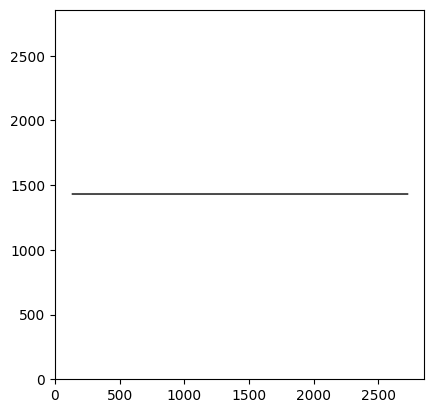

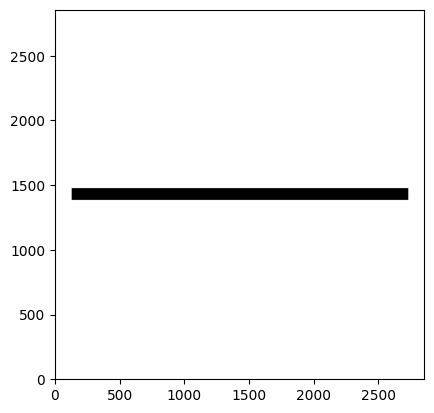

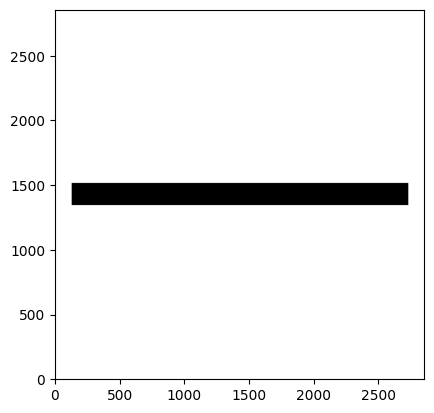

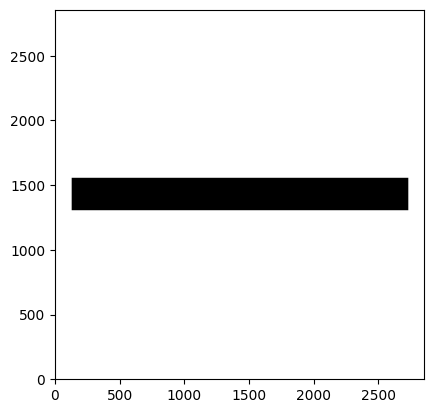

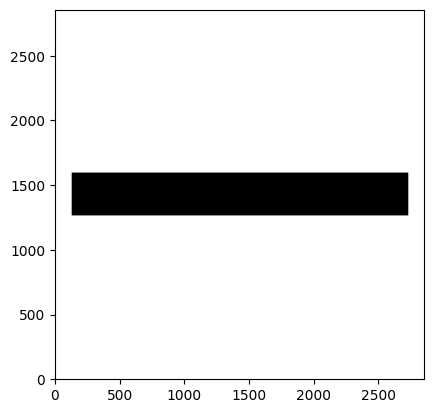

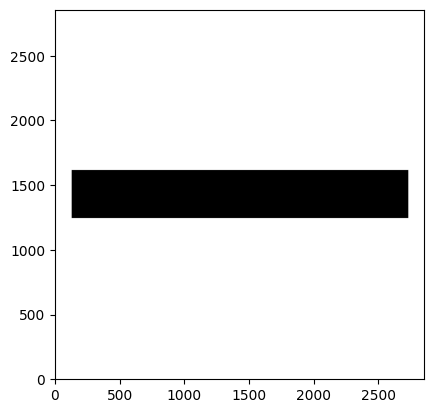

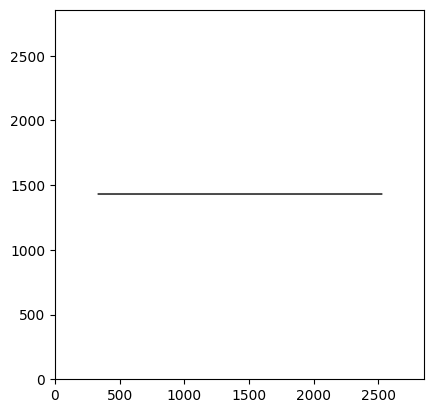

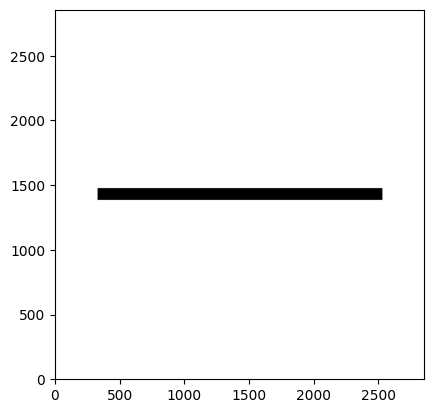

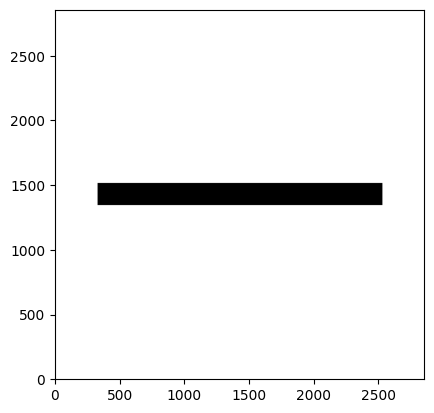

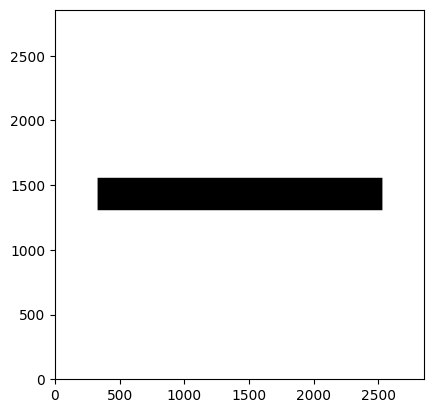

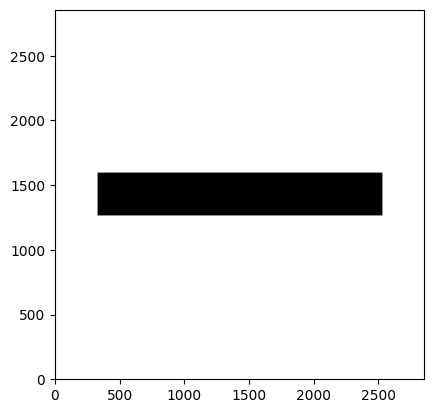

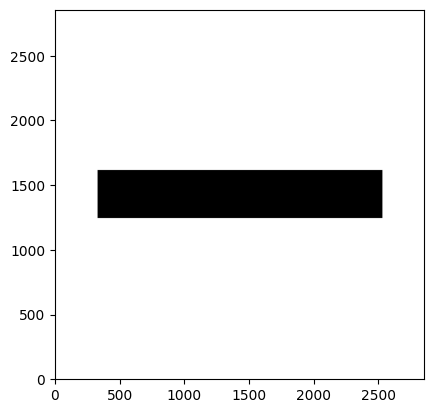

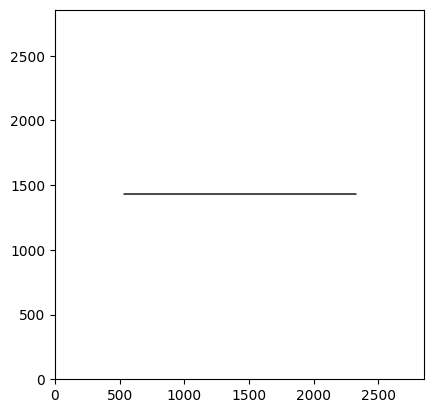

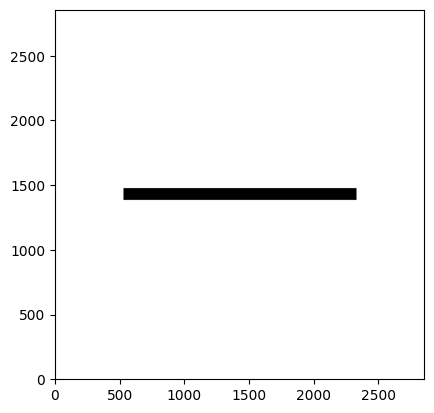

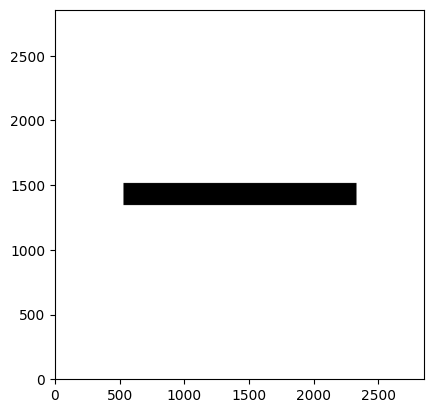

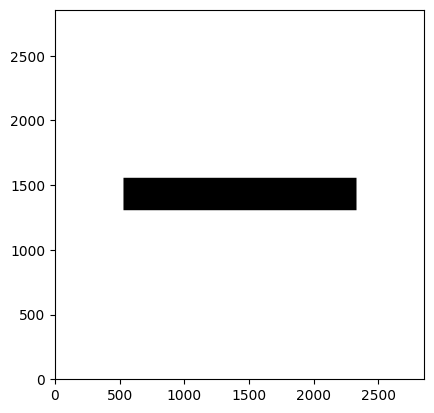

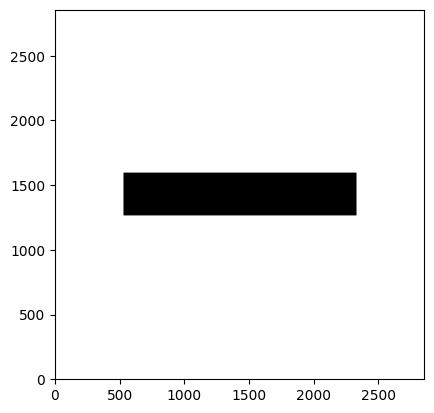

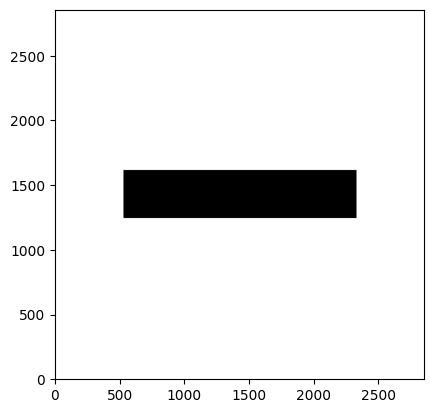

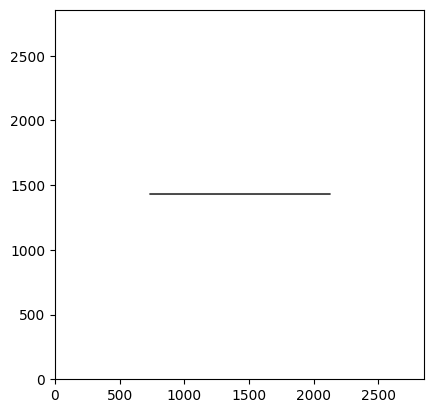

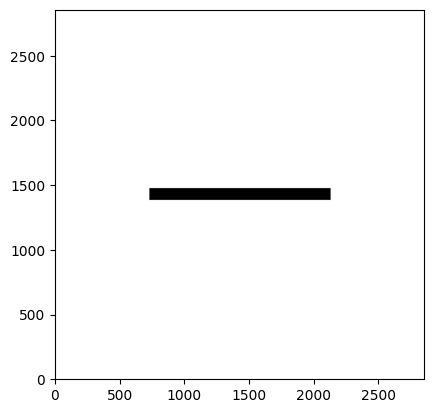

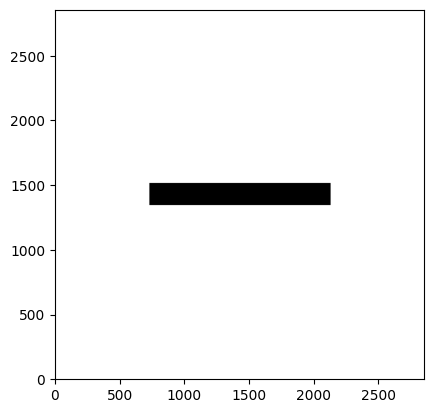

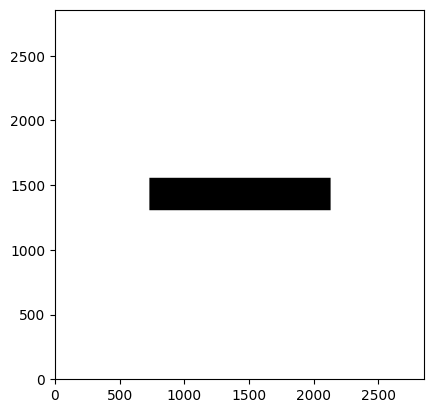

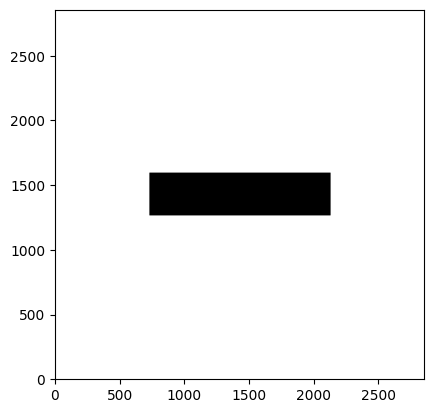

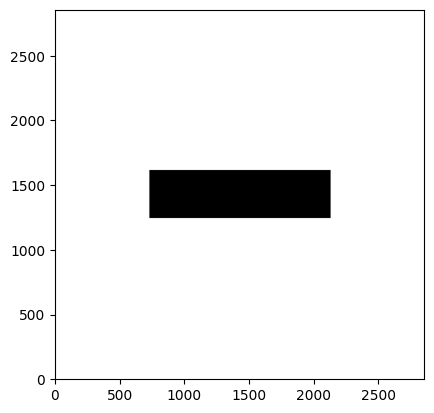

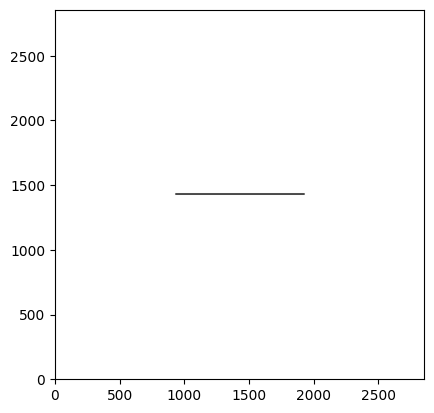

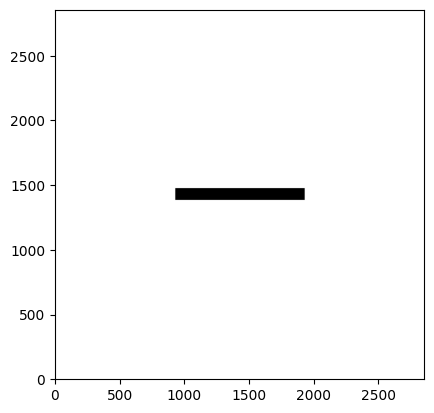

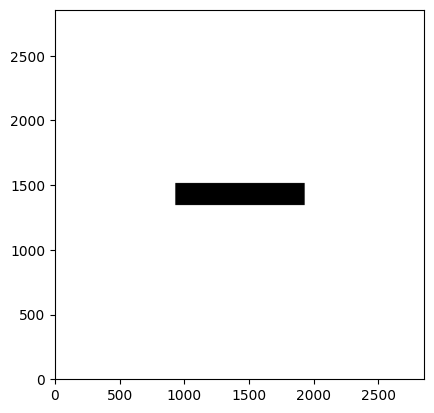

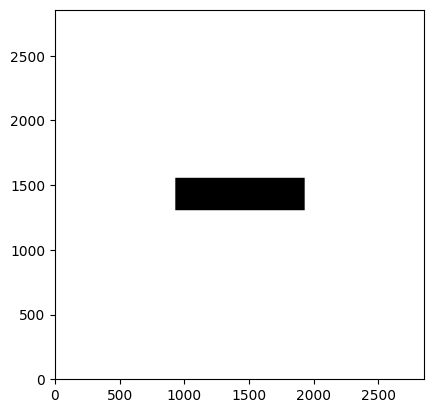

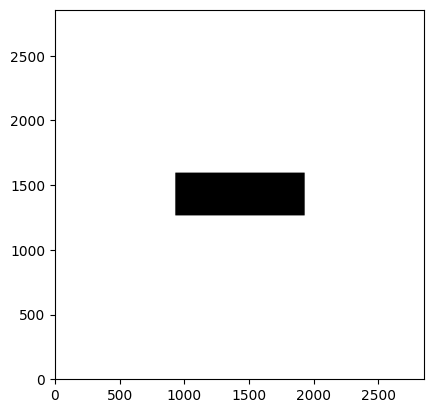

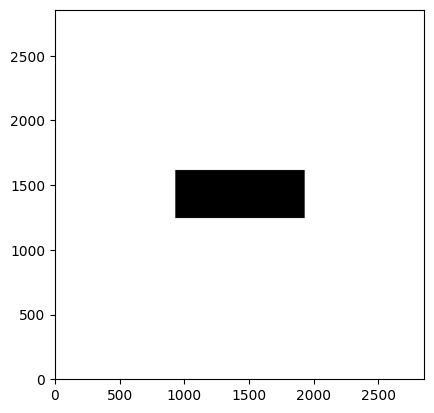

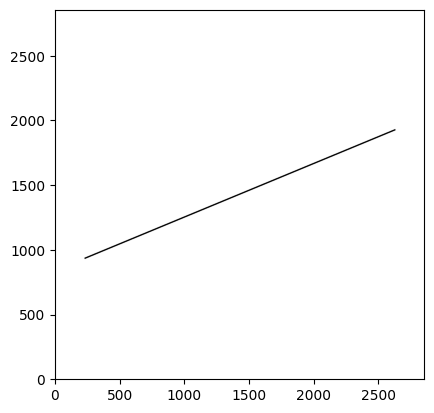

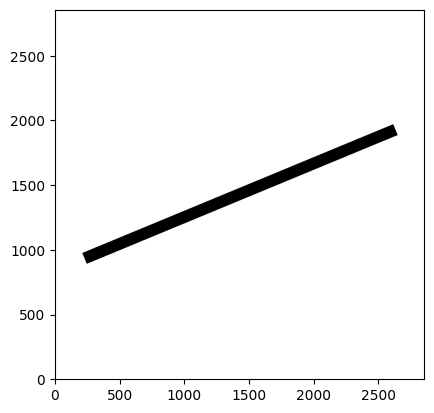

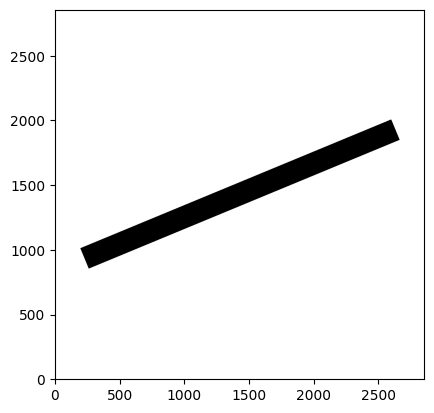

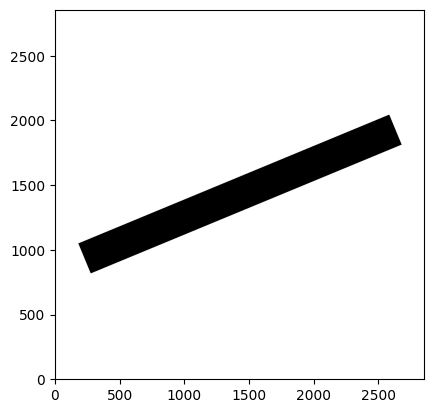

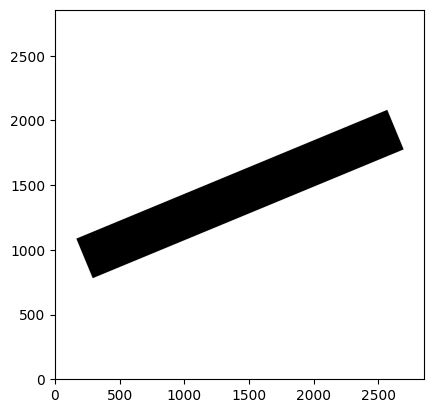

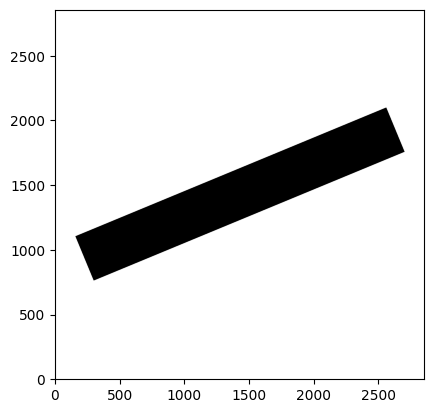

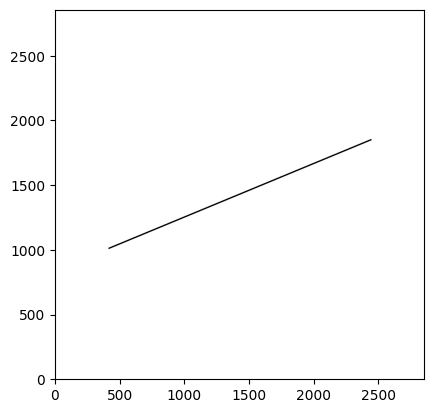

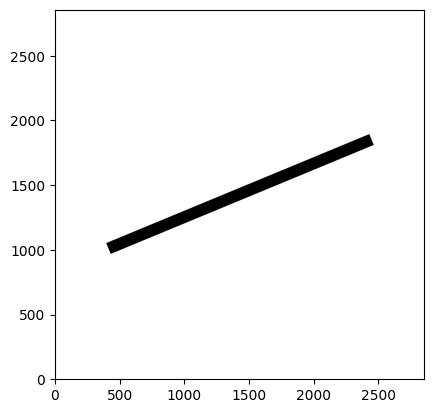

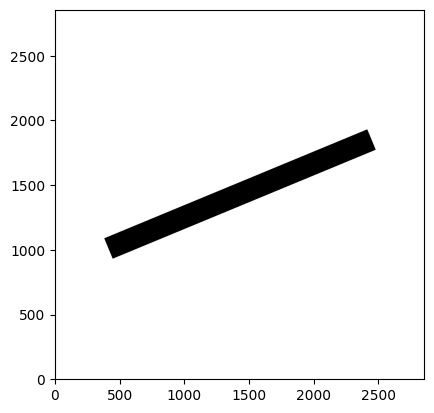

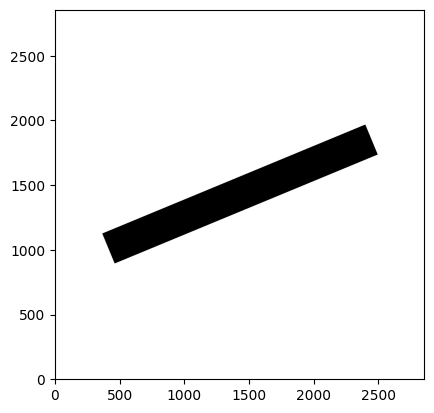

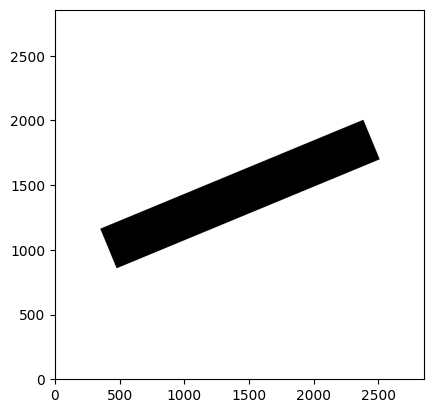

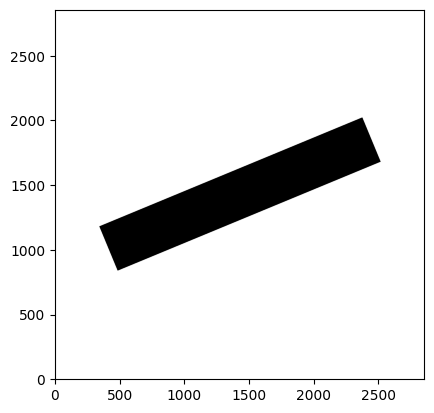

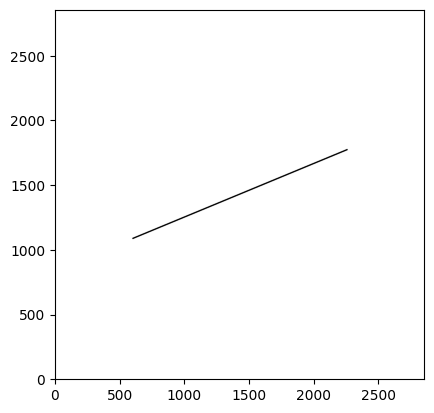

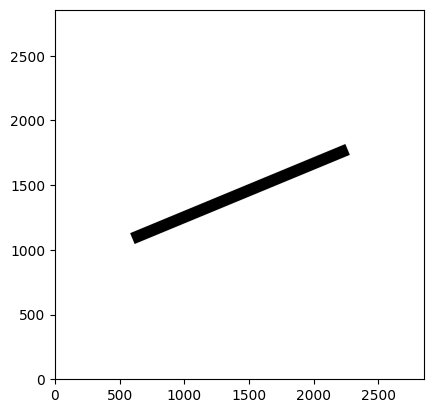

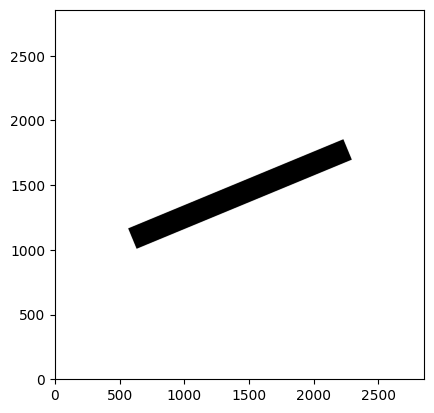

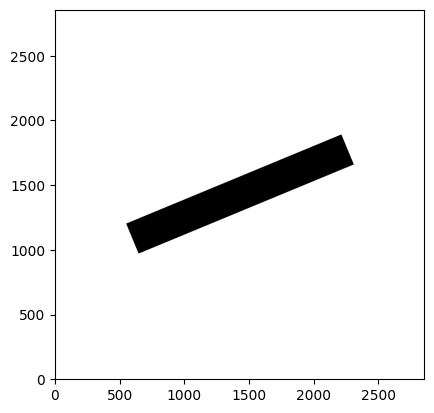

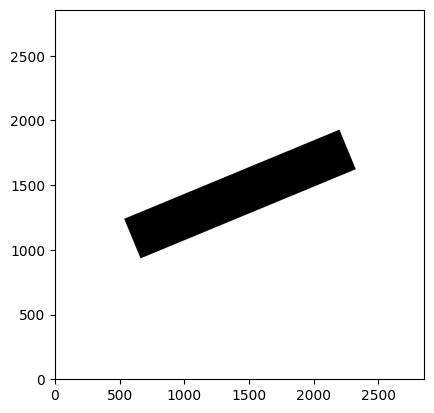

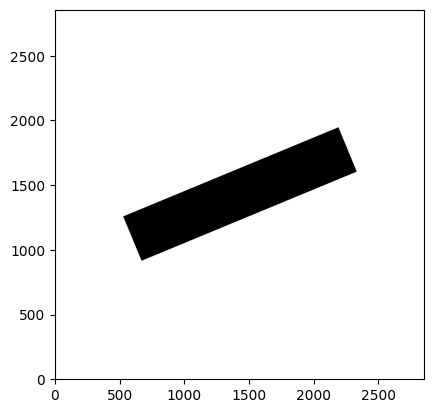

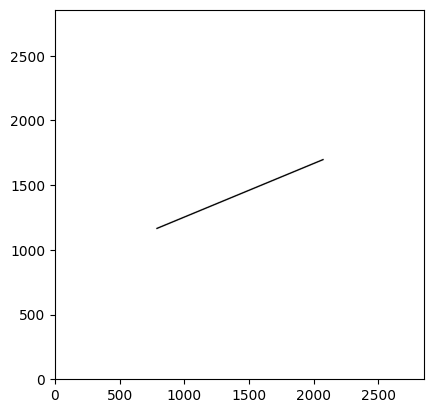

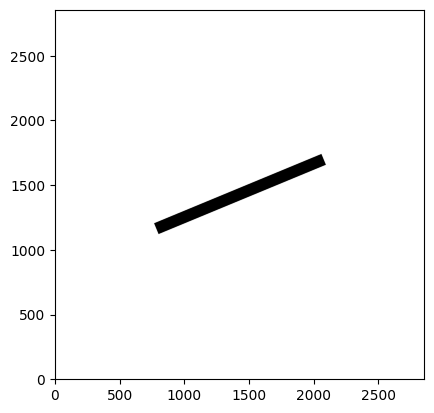

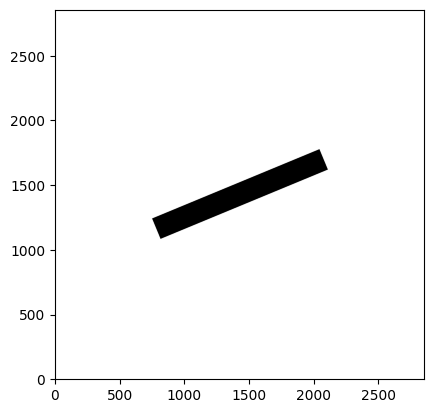

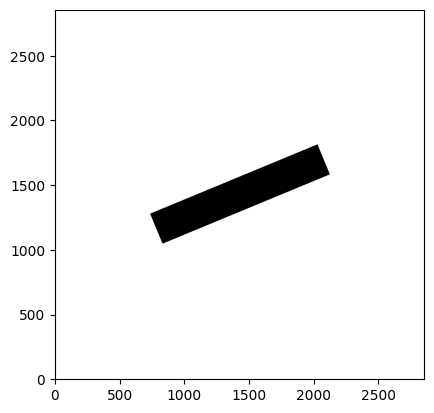

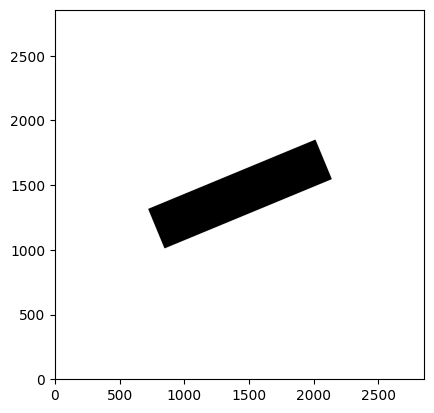

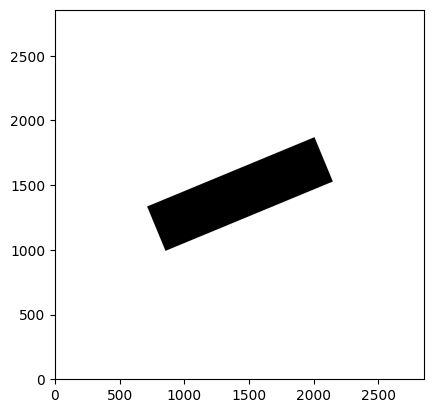

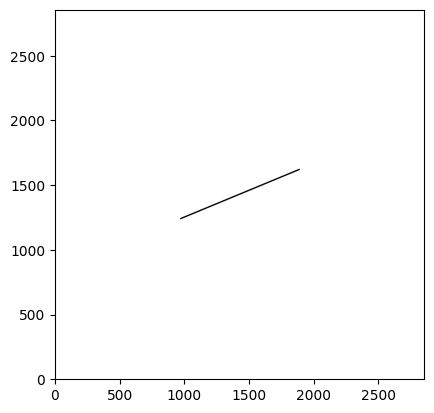

KeyboardInterrupt: 

In [4]:
## make bars

factor = 4
X, Y = np.meshgrid(np.linspace(0,714*factor,714*factor), np.linspace(0,714*factor,714*factor))
rad_increment = np.pi/8
#lengths = [700, 600, 500, 400, 300]  # if we use 6 lengths[700, 600, 500, 400, 300, 200]
lengths = [650, 550, 450, 350, 250] 

# widths = [3, 23, 43, 63]  # if we use 5 widths [3, 23, 43, 63, 83]
widths = [3, 23, 43, 63, 83, 93]

angles = np.array([0,1,2,3,4,5,6,7])*rad_increment

for theta in angles:
    for l in lengths:
        for w in widths:
            Z = oblong(X, Y, (714*factor)/2, (714*factor)/2, l*factor, w*factor, theta) # np.pi/6)
            plt.figure()
            plt.imshow(Z, origin='lower', cmap='Greys')
            plt.show()
            Z = (1-Z)*1.0
            Z[Z==1]=.5; 
            Z = np.uint8(Z * 255)
            im = Image.fromarray(Z, mode='L')
            im = im.resize((714, 714), resample = Image.BILINEAR)
            #test = im.getpixel((307,307))

            im = im.transpose(Image.FLIP_LEFT_RIGHT)
            filename = '/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/data/nsddata_stimuli/stimuli/attention_images/bar_%05.1fdeg_%sL_%02dW.png' %(math.degrees(theta), l, w)
            im.save(filename)
            plt.close()

            

In [4]:
## make crosses 

X, Y = np.meshgrid(np.linspace(0,714*factor,714*factor), np.linspace(0,714*factor,714*factor))
rad_increment = np.pi/8
#lengths = [700, 600, 500, 400, 300]  # if we use 6 lengths[700, 600, 500, 400, 300, 200]
lengths = [650, 550, 450, 350, 250] 

# widths = [3, 23, 43, 63]  # if we use 5 widths [3, 23, 43, 63, 83]
widths = [3, 23, 43, 63, 83, 93]

angles = np.array([0,1,2,3])*rad_increment

for theta in angles:
    for l in lengths:
        for w in widths:
            Z = cross(X, Y, (714*factor)/2, (714*factor)/2, l*factor, w*factor, theta) # np.pi/6)
            plt.figure()
            plt.imshow(Z, origin='lower', cmap='Greys')
            Z = (1-Z)*1.0
            Z[Z==1]=.5; 
            Z = np.uint8(Z * 255)
            im = Image.fromarray(Z, mode='L')
            im = im.resize((714, 714), resample = Image.BILINEAR)
            im = im.transpose(Image.FLIP_LEFT_RIGHT)
            filename = '/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/data/nsddata_stimuli/stimuli/attention_images/crs_%05.1fdeg_%sL_%02dW.png' %(math.degrees(theta), l, w)

            im.save(filename)
            plt.close()


In [5]:
# n = 4
# X, Y = np.meshgrid(np.linspace(0,714*n,714*n), np.linspace(0,714*n,714*n))
# Z = oblong(X, Y, (714*n)/2, (714*n)/2, 700*n, 3*n , rad_increment)
# plt.imshow(Z, origin='lower', cmap='Greys')
# Z = Z*1.0
# print Z

# im = Image.fromarray(Z)
# im = im.resize((714, 714), resample = Image.BILINEAR)
# print im.size
# print type(im)
# # im.save('test_saving.png')
# misc.imsave('saving_test.png', im)


In [12]:
import os
import shutil
from tqdm import tqdm

source_dir = '/export/raid1/home/surly/raid4/kendrick-data/nsd/nsddata_stimuli/stimuli/nsdimagery/allstim'
destination_dir = '/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/data/nsddata_stimuli/stimuli/attention_images'


# Get a list of all files in the source directory
file_list = os.listdir(source_dir)

# Iterate over the files and copy only the PNG files to the destination directory
for file in tqdm(file_list):
    if file.endswith('.png'):
        source_file = os.path.join(source_dir, file)
        destination_file = os.path.join(destination_dir, file)
        shutil.copy(source_file, destination_file)


100%|██████████| 1149/1149 [23:24<00:00,  1.22s/it]
